#What the deffiernce between machine learning and deep learning


Deep Learning is a subset of Machine Learning, and Machine Learning is a subset of Artificial Intelligence (AI).

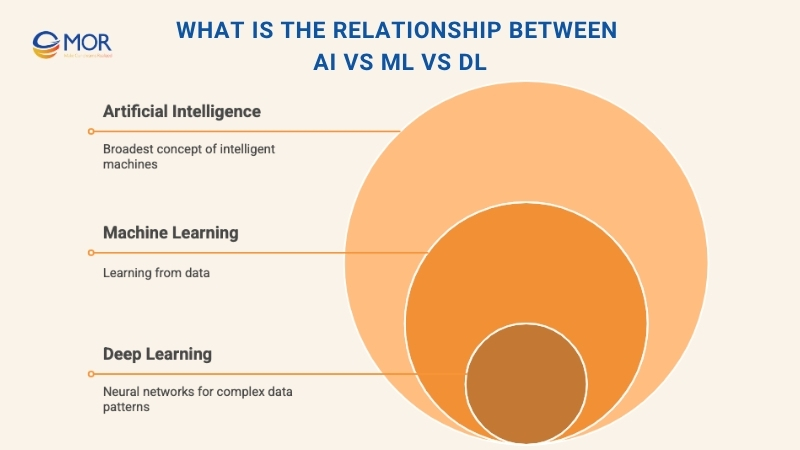

--------------

The main difference between Machine Learning (ML) and Deep Learning (DL) is how they learn patterns from data, how much feature engineering they need, and the complexity of the models they use.

ML -- need Feature Engieering

DL -- don't need Feature Engineering

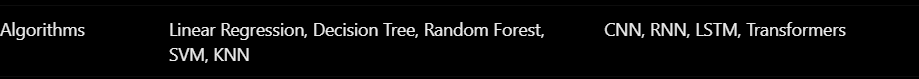




-----------------------



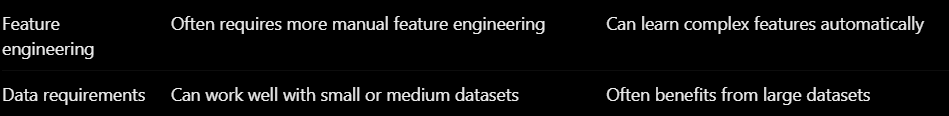



---------------------



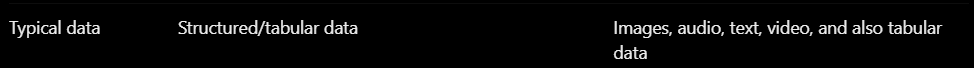

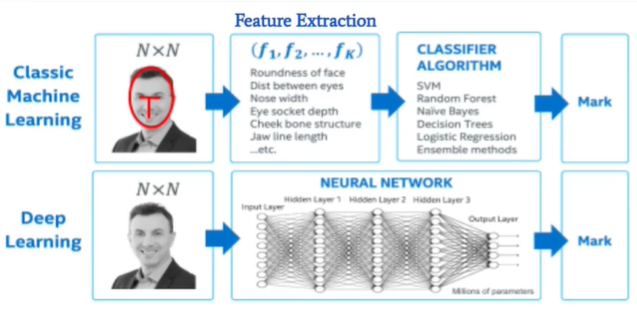

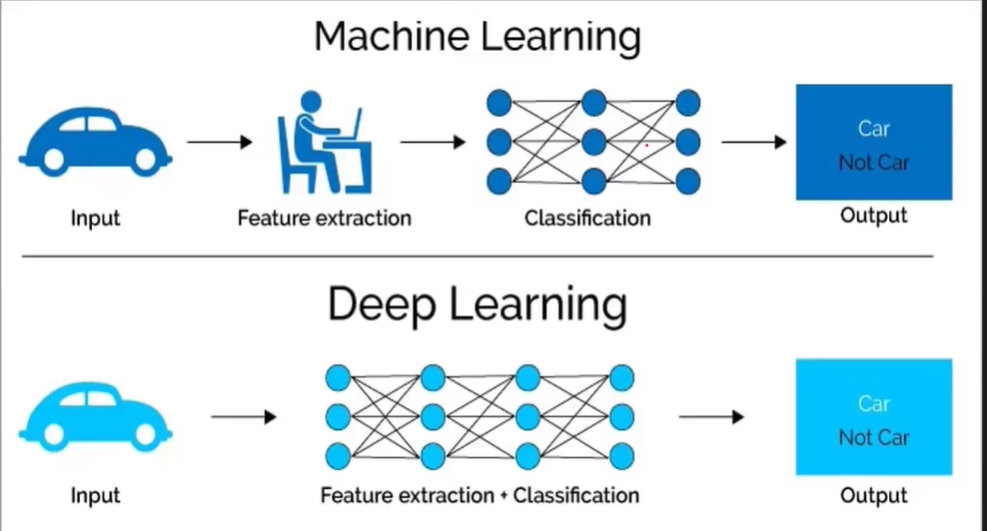

-------------------

#Example

### Imagine you're working with Vodafone and want to predict which customers will make churn.


Approach ML


Approach DL


----------------

1. Approach ML :
Customer age



Number of active lines



Monthly revenue



Contract duration



Number of complaints



Churn status (Yes/No)




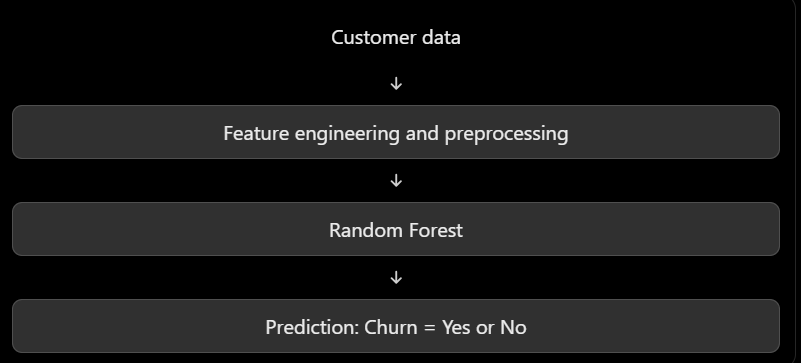

--------------

2. Approach DL :


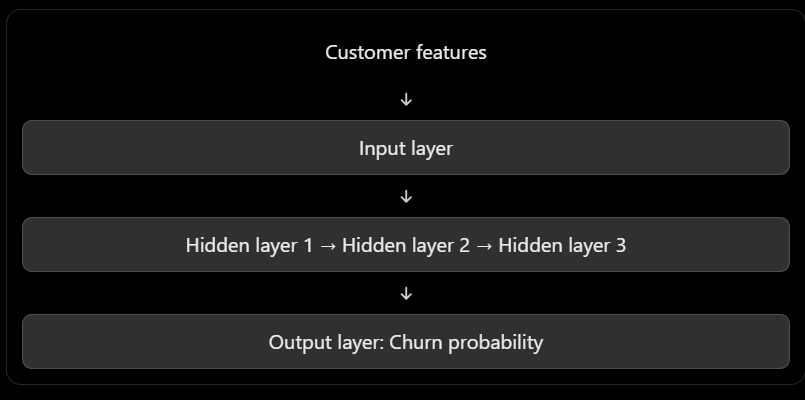

what is the shape of NN ?

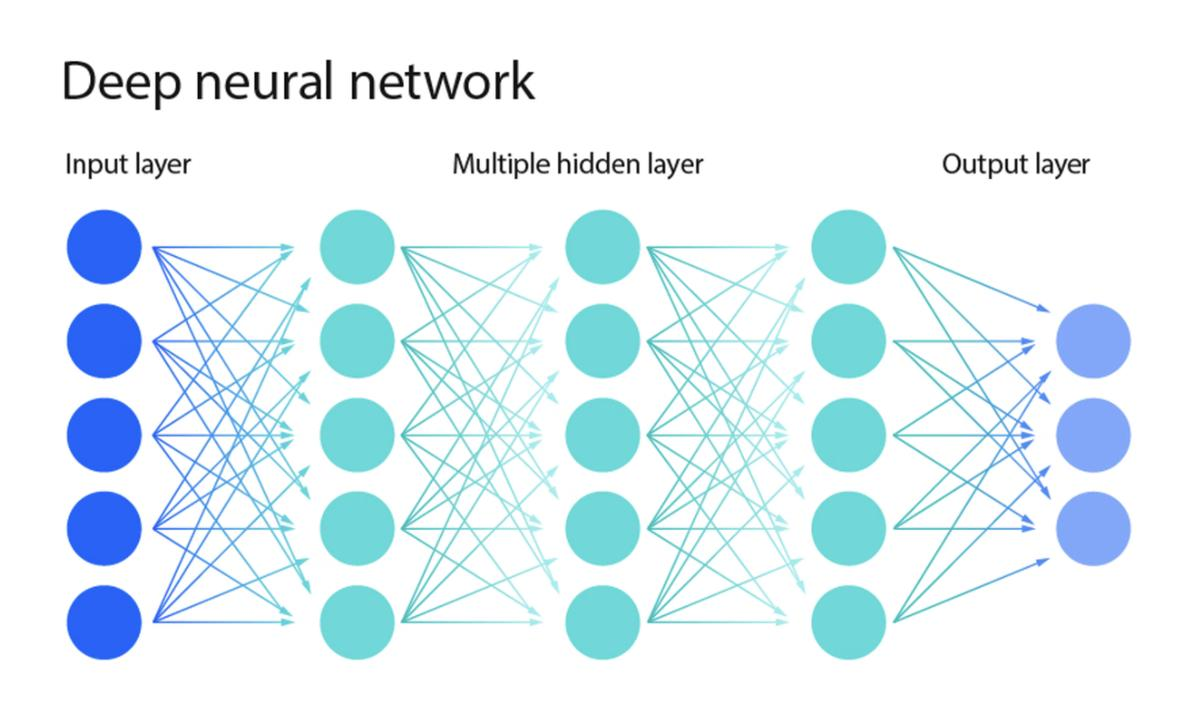

Input layer: Receives the features.



Hidden layers: Learn patterns.



Output layer: Produces the prediction.


EX : image Recognition


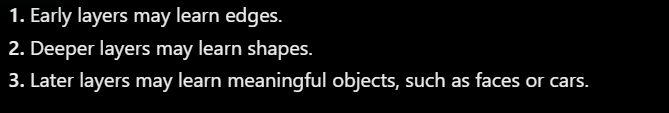

----------------------

Why is feature engineering different?
Consider an image classification problem: identifying cats and dogs.
- Traditional ML: You might extract features such as color histograms, edges, and texture, then feed them into an SVM or another classifier.
- DL: A CNN can learn useful visual features directly from the pixel data.

----------------------


# Examples of ML vs. DL algorithms

Machine Learning

Linear Regression, Logistic Regression, Decision Trees, Random Forest, SVM, KNN, XGBoost, and LightGBM

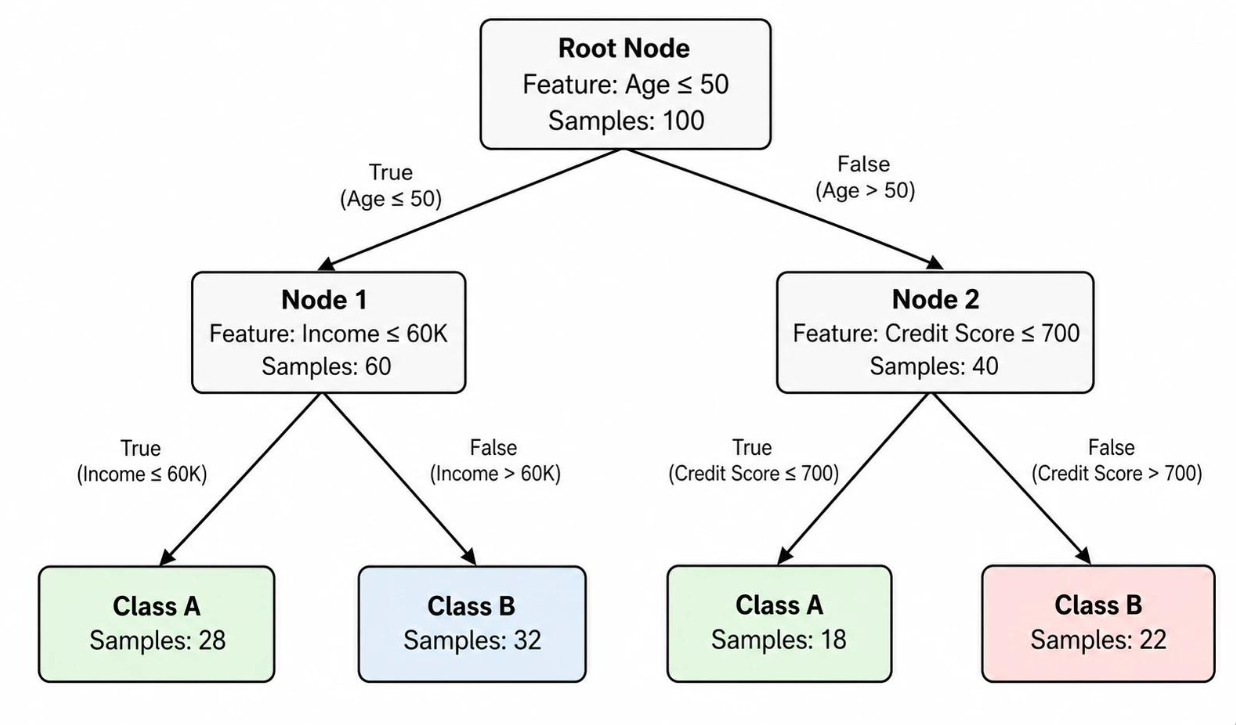

Deep Learning

Artificial Neural Networks (ANNs), CNNs, RNNs, LSTMs, Transformers, and architectures used in modern language and vision models.

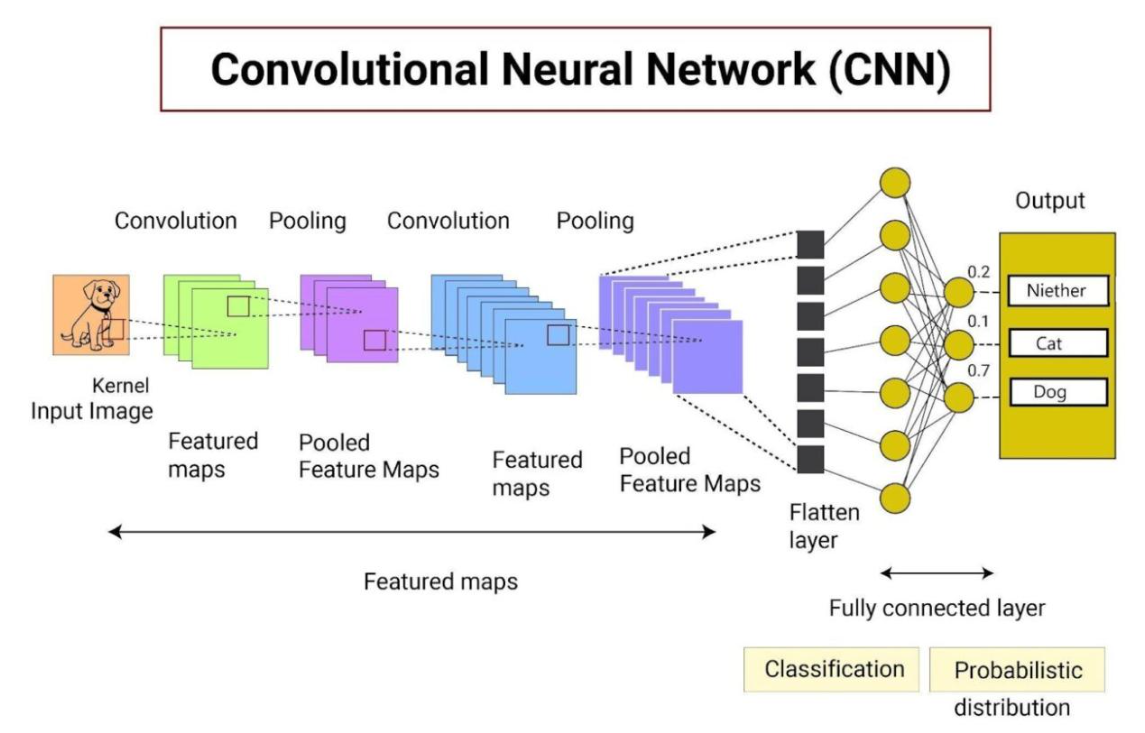

### when use DL and when ML ?

1. Predicting customer churn from Excel or SQL tables

2. Predicting house prices from structured columns

3. Image classification

4. Large-scale language models and generative AI


5. Complex text, image, or audio patterns


Important Notes



ML: You often design useful features, then train an algorithm to learn the relationship between those features and the target.



DL: You train a multilayer neural network that can learn both useful representations and the relationship to the target

# Neural Network ?

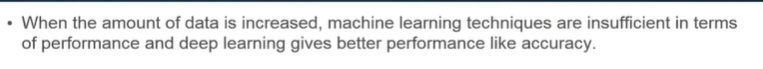

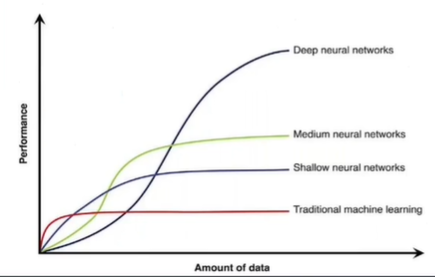

### Foundation of DL ?


Neuron



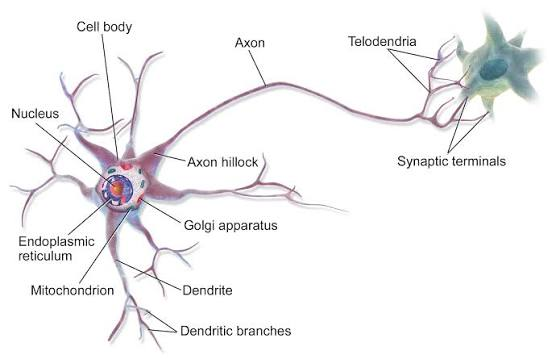


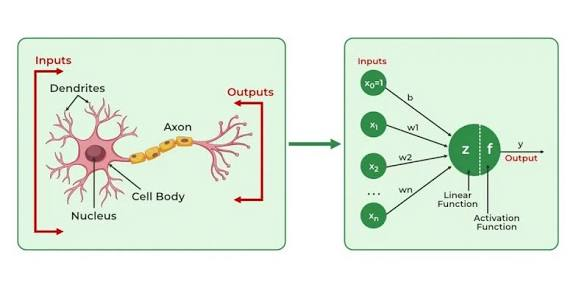

Neron ( perceptron ) it is very small element in Neural Network




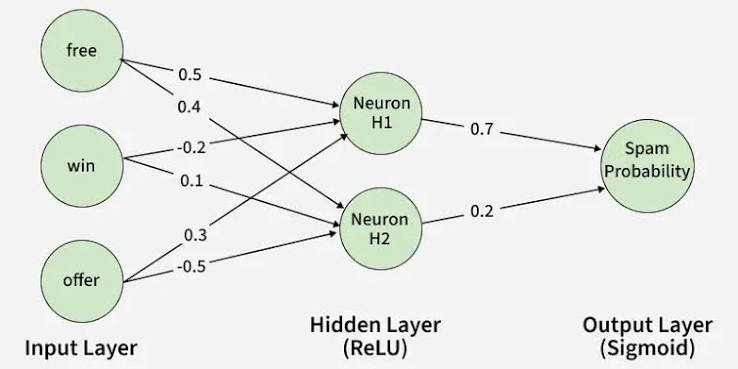



```
# This is formatted as code
```

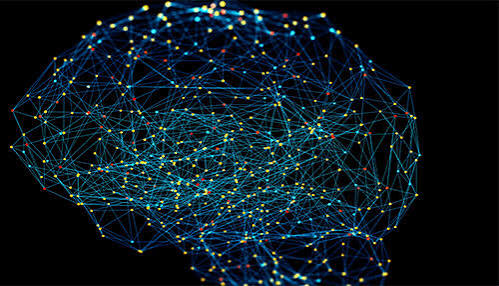

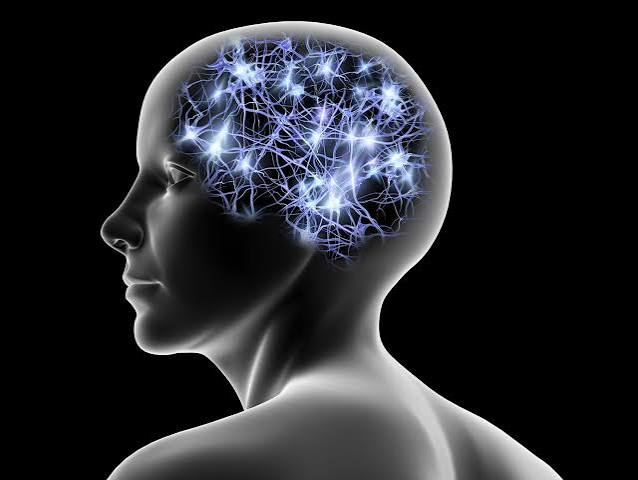

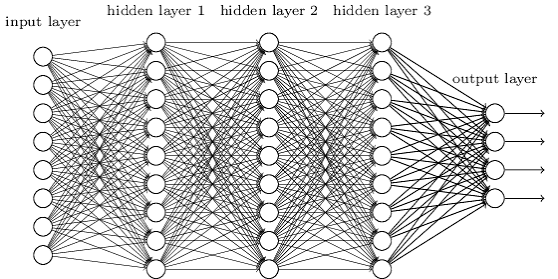

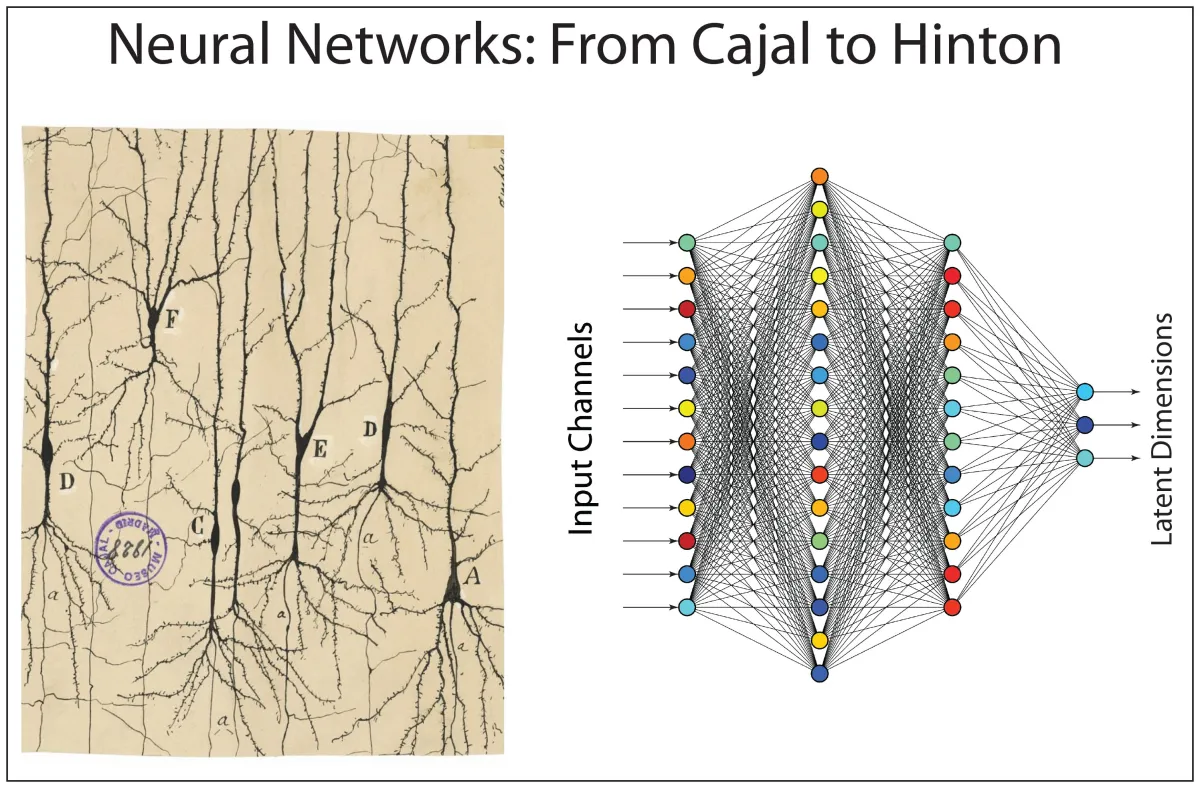

1. Every Neuron has a weight

2. the output of each Neuron is the input for the next Neuron

3. based on each weight , the neural network decide what the useful information


4. output must pass through Activation function


5. ANN (Artificial Neural Netowrk ) is combinations of neurons




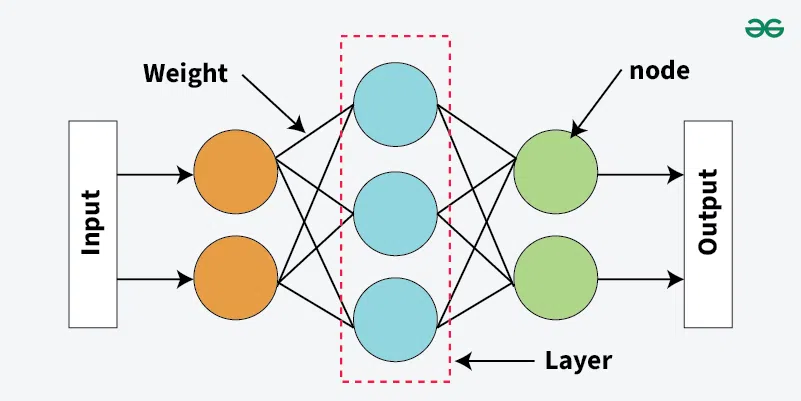

-----------------

1. Shallow Neural Network : with only one hidden layer
2. Deep Neural Network : has many hidden layers


the complexity of NN increase with the number of hidden layers




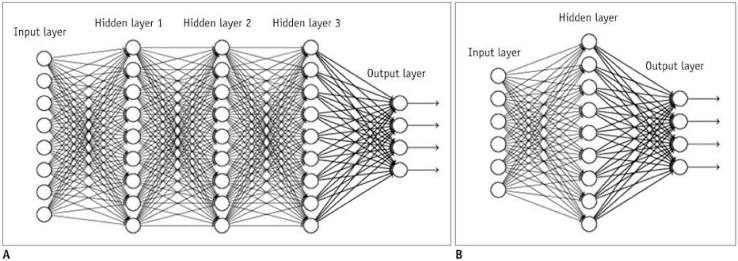


------------------

#Bias ?

bias numeric value trainable parameter

added to each sum of inputs * weights

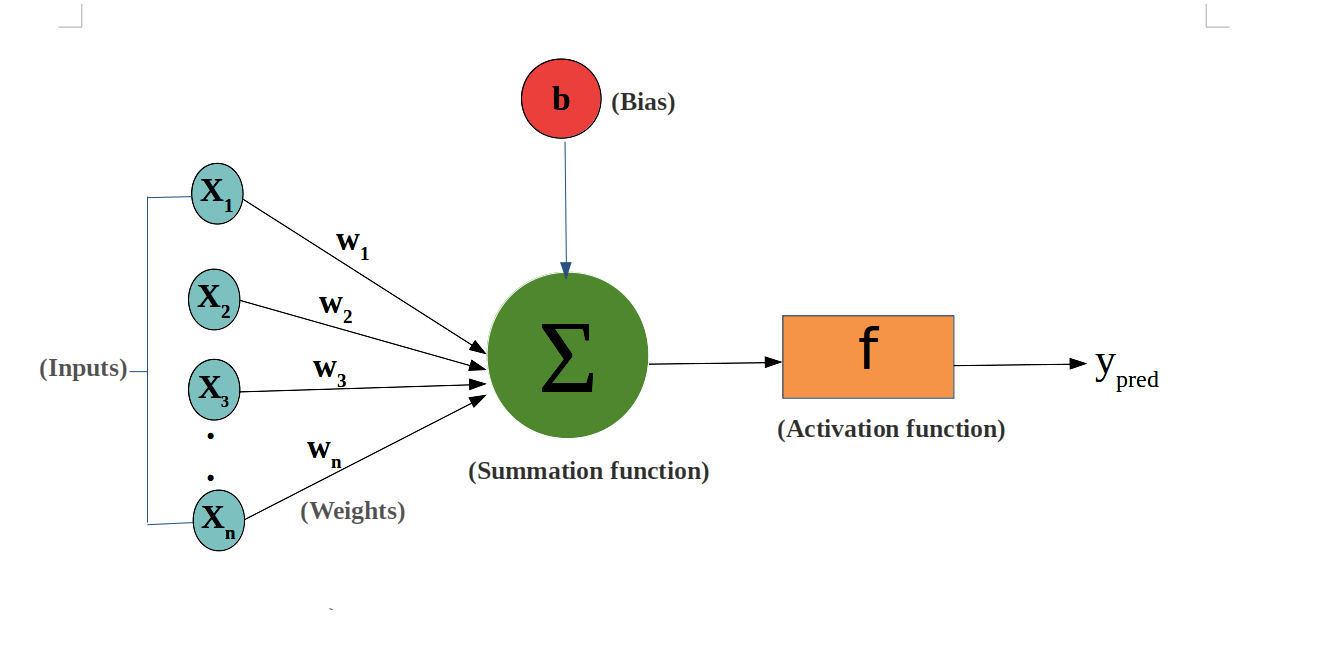

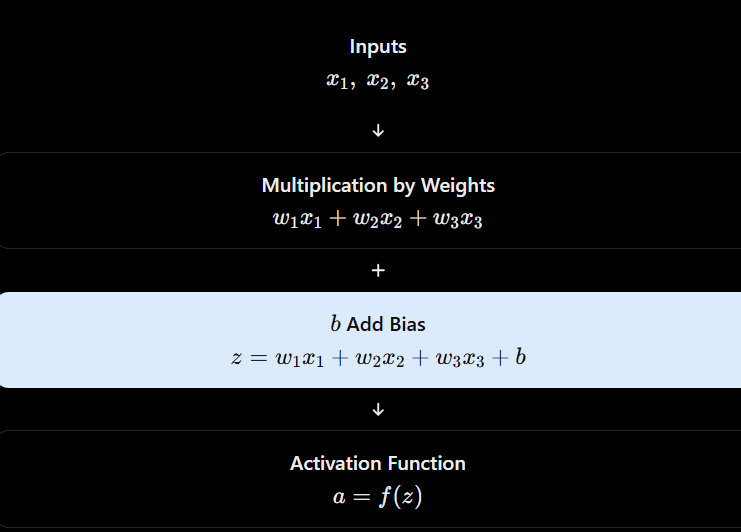

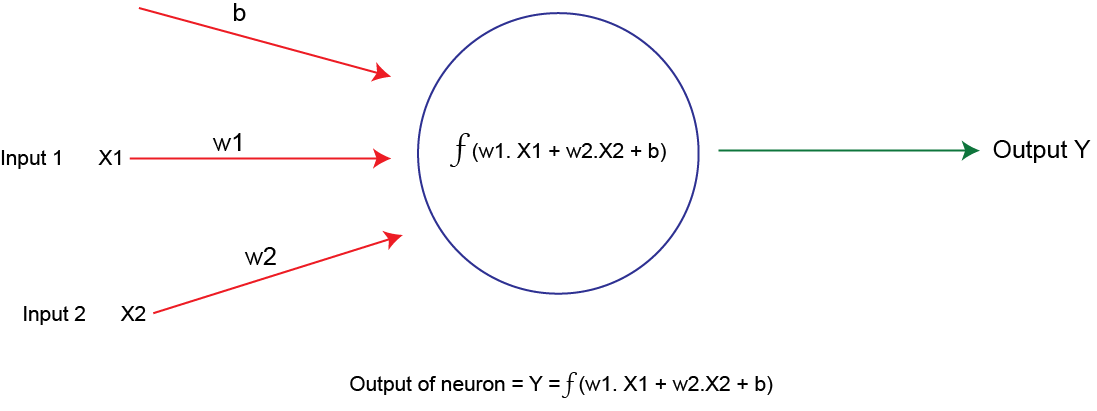

# activation function ?

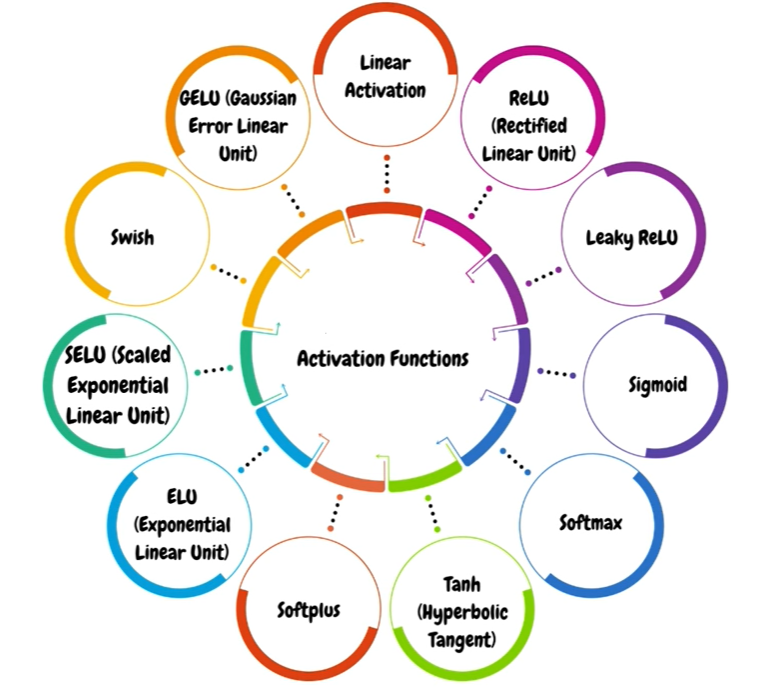

without activation function , even if we add many layer the NN will be large linear Equation


So we need something to convert the linear equation to non-linear Equation


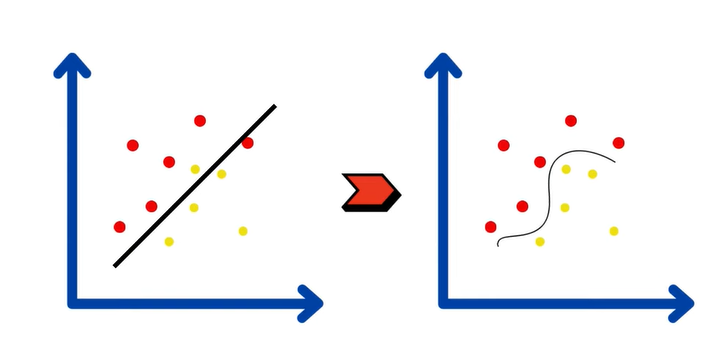

activation Function : 3 Rules

1. help NN to Learn in non-linear relation
2. Transform Neurons's output
3. generate outputlayer

------------------------------

Activation Function بتساعد الشبكة تفهم علاقات مش مجرد جمع وضرب




1. threshold
2. Sigmoid
3. tanh
4. relu
5. linear / indentiy


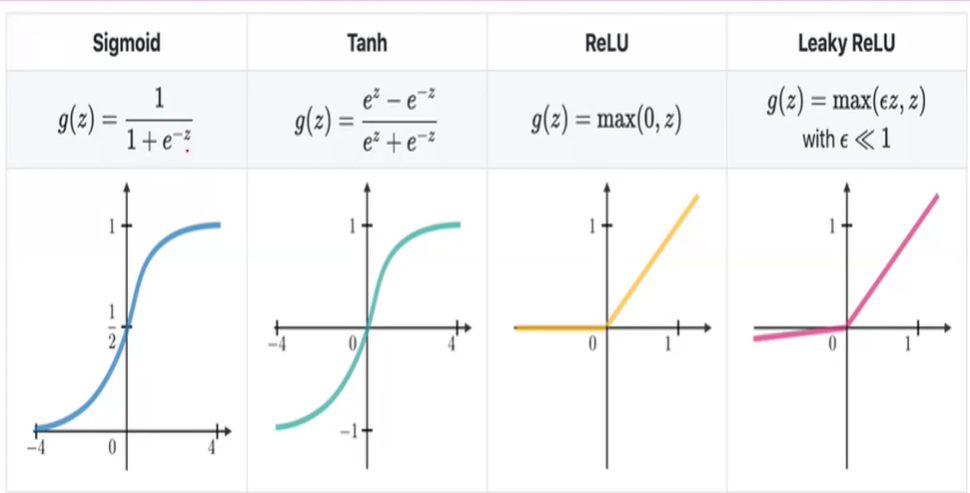

# Forword propagartion and backpropagation

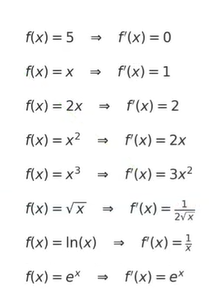

#NN Manual  

### 3 features
### hidden layer Relu


In [ ]:
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
# 1. Load Dataset
data = load_breast_cancer()

X = data.data
y = data.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [ ]:
# 2. Split X and y into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
# 3. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:

# 4. Initialize Weights
np.random.seed(42)

n_features = X_train.shape[1]

# One hidden layer with 4 neurons
W1 = np.random.randn(n_features, 4) * 0.1
b1 = np.zeros(4)

W2 = np.random.randn(4) * 0.1
b2 = 0.0

learning_rate = 0.01
epochs = 100

In [ ]:
# 5. Training
for epoch in range(epochs):

    total_loss = 0

    for i in range(len(X_train)):

        # Get one training sample
        X_sample = X_train[i]
        actual_y = y_train[i]

        # -------------------------
        # Forward Propagation
        # -------------------------

        hidden_input = X_sample @ W1 + b1
        hidden = 1 / (1 + np.exp(-hidden_input))

        output_input = hidden @ W2 + b2
        y_hat = 1 / (1 + np.exp(-output_input))

        # -------------------------
        # Calculate Loss
        # ------------------------

        loss = -(
            actual_y * np.log(y_hat)
            + (1 - actual_y) * np.log(1 - y_hat)
        )

        total_loss += loss

        # -------------------------
        # Backpropagation
        # -------------------------

        d_loss_d_output_input = y_hat - actual_y

        d_loss_d_W2 = hidden * d_loss_d_output_input
        d_loss_d_b2 = d_loss_d_output_input

        d_loss_d_hidden_input = (
            d_loss_d_output_input
            * W2
            * hidden * (1 - hidden)
        )

        d_loss_d_W1 = np.outer(
            X_sample, d_loss_d_hidden_input
        )

        d_loss_d_b1 = d_loss_d_hidden_input

        # -------------------------
        # Update Weights
        # -------------------------

        W2 = W2 - learning_rate * d_loss_d_W2
        b2 = b2 - learning_rate * d_loss_d_b2

        W1 = W1 - learning_rate * d_loss_d_W1
        b1 = b1 - learning_rate * d_loss_d_b1

    if (epoch + 1) % 10 == 0:
        average_loss = total_loss / len(X_train)
        print("Epoch:", epoch + 1, "Loss:", average_loss)


Epoch: 10 Loss: 0.04822622188122494
Epoch: 20 Loss: 0.03667997002520559
Epoch: 30 Loss: 0.03283882898505658
Epoch: 40 Loss: 0.030820334475652716
Epoch: 50 Loss: 0.029516651757666466
Epoch: 60 Loss: 0.0285682435374725
Epoch: 70 Loss: 0.02782161706770388
Epoch: 80 Loss: 0.027202466673678833
Epoch: 90 Loss: 0.026670338094566873
Epoch: 100 Loss: 0.02620100300840779


In [ ]:

# 6. Testing
predictions = []

for X_sample in X_test:

    hidden_input = X_sample @ W1 + b1
    hidden = 1 / (1 + np.exp(-hidden_input))

    output_input = hidden @ W2 + b2
    y_hat = 1 / (1 + np.exp(-output_input))

    predicted_class = 1 if y_hat >= 0.5 else 0
    predictions.append(predicted_class)

# 7. Evaluation
print("\nAccuracy:", accuracy_score(y_test, predictions))



Accuracy: 0.9649122807017544
